In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for SQL window functions and ranking loaded successfully.")

Global libraries for SQL window functions and ranking loaded successfully.


# Table of Contents
- 1. Ranking Functions (`ROW_NUMBER`, `RANK`, `DENSE_RANK`)
- 2. Offset Functions (`LAG`, `LEAD`)
- 3. Running Totals and Moving Averages via Frames
- 4. FIRST_VALUE and LAST_VALUE Extractions

Ranking Window Function Results:
       name department  salary  row_num  rk  dense_rk
0      Eve         HR   75000        1   1         1
1     Dave         HR   60000        2   2         2
2    Frank         HR   55000        3   3         3
3    Alice         IT   90000        1   1         1
4      Bob         IT   85000        2   2         2
5  Charlie         IT   85000        3   2         2


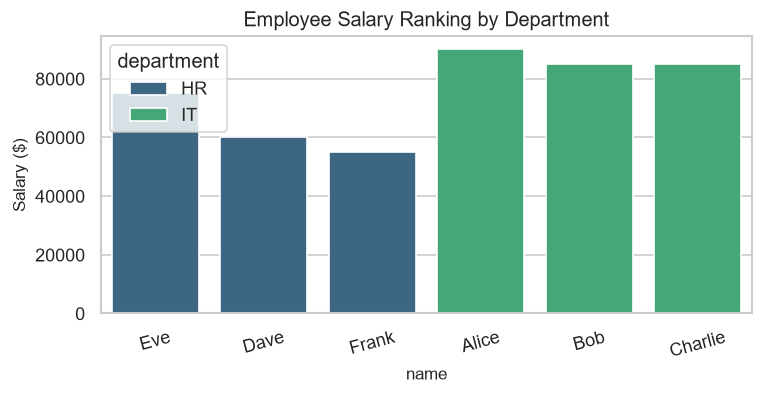

In [3]:
# 1. Ranking Functions (`ROW_NUMBER`, `RANK`, `DENSE_RANK`)
# 6. & 7. Implementation and Visualization
conn = sqlite3.connect(':memory:')
df_emp = pd.DataFrame({
    'department': ['IT', 'IT', 'IT', 'HR', 'HR', 'HR'],
    'name': ['Alice', 'Bob', 'Charlie', 'Dave', 'Eve', 'Frank'],
    'salary': [90000, 85000, 85000, 60000, 75000, 55000]
})
df_emp.to_sql('employees', conn, index=False, if_exists='replace')

query_rank = '''
    SELECT name, department, salary,
           ROW_NUMBER() OVER (PARTITION BY department ORDER BY salary DESC) as row_num,
           RANK() OVER (PARTITION BY department ORDER BY salary DESC) as rk,
           DENSE_RANK() OVER (PARTITION BY department ORDER BY salary DESC) as dense_rk
    FROM employees
'''
res_rank = pd.read_sql(query_rank, conn)
print("Ranking Window Function Results:\n", res_rank)

# Visualization
plt.figure(figsize=(7, 3))
sns.barplot(x='name', y='salary', hue='department', data=res_rank, palette='viridis', errorbar=None)
plt.title('Employee Salary Ranking by Department')
plt.ylabel('Salary ($)')
plt.xticks(rotation=15)
plt.show()

Given ordered series $x_1, x_2, \dots, x_N$, offset function with lag $k$ is defined as:
$$\text{LAG}(x_t, k) = x_{t-k}, \quad \text{LEAD}(x_t, k) = x_{t+k}$$

Offset Function Results:
          date  price  prev_price  price_change
0  2026-01-01    100         NaN           NaN
1  2026-01-02    105       100.0           5.0
2  2026-01-03    102       105.0          -3.0
3  2026-01-04    110       102.0           8.0


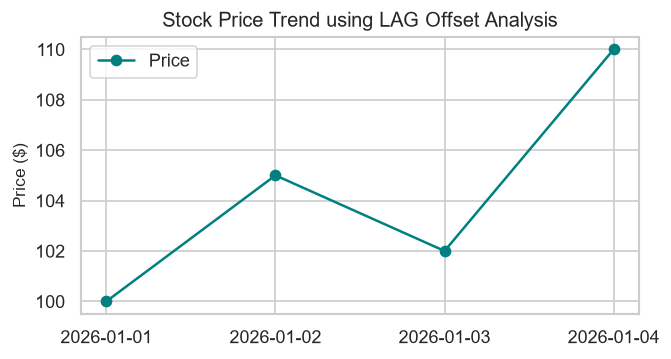

In [5]:
# 2. Offset Functions (`LAG`, `LEAD`)
df_stock = pd.DataFrame({
    'date': ['2026-01-01', '2026-01-02', '2026-01-03', '2026-01-04'],
    'price': [100, 105, 102, 110]
})
df_stock.to_sql('stock', conn, index=False, if_exists='replace')

query_offset = '''
    SELECT date, price,
           LAG(price, 1) OVER (ORDER BY date) as prev_price,
           price - LAG(price, 1) OVER (ORDER BY date) as price_change
    FROM stock
'''
res_offset = pd.read_sql(query_offset, conn)
print("Offset Function Results:\n", res_offset)

# Visualization
plt.figure(figsize=(6, 3))
plt.plot(res_offset['date'], res_offset['price'], marker='o', label='Price', color='teal')
plt.title('Stock Price Trend using LAG Offset Analysis')
plt.ylabel('Price ($)')
plt.legend()
plt.show()

Window Frame Aggregations:
    day  revenue  running_total  moving_avg
0    1      100            100       100.0
1    2      150            250       125.0
2    3      200            450       175.0
3    4      120            570       160.0
4    5      300            870       210.0


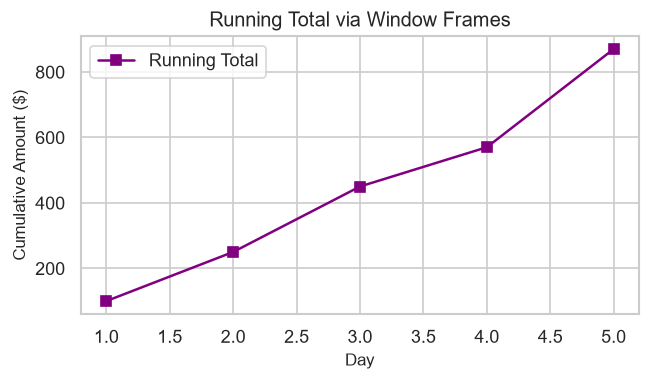

In [6]:
# 3. Running Totals and Moving Averages via Frames
# 6. & 7. Implementation and Visualization
df_rev = pd.DataFrame({
    'day': [1, 2, 3, 4, 5],
    'revenue': [100, 150, 200, 120, 300]
})
df_rev.to_sql('revenue_log', conn, index=False, if_exists='replace')

query_frame = '''
    SELECT day, revenue,
           SUM(revenue) OVER (ORDER BY day ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) as running_total,
           AVG(revenue) OVER (ORDER BY day ROWS BETWEEN 1 PRECEDING AND CURRENT ROW) as moving_avg
    FROM revenue_log
'''
res_frame = pd.read_sql(query_frame, conn)
print(
    "Window Frame Aggregations:\n",
    res_frame,
)

# Visualization
plt.figure(figsize=(6, 3))
plt.plot(res_frame['day'], res_frame['running_total'], marker='s', color='purple', label='Running Total')
plt.title('Running Total via Window Frames')
plt.xlabel('Day')
plt.ylabel('Cumulative Amount ($)')
plt.legend()
plt.show()

First Value Extraction Results:
    customer_id  month    tier initial_tier final_tier
0            1      1   Basic        Basic       Gold
1            1      2  Silver        Basic       Gold
2            1      3    Gold        Basic       Gold
3            2      1  Silver       Silver       Gold
4            2      2    Gold       Silver       Gold


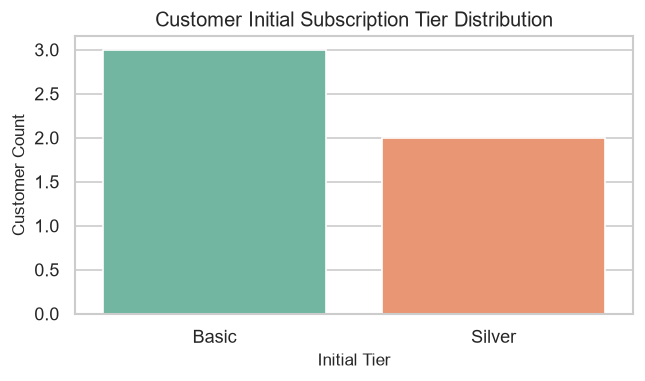

In [7]:
# 4. FIRST_VALUE and LAST_VALUE Extractions
# 6. & 7. Implementation and Visualization
df_subs = pd.DataFrame({
    'customer_id': [1, 1, 1, 2, 2],
    'month': [1, 2, 3, 1, 2],
    'tier': ['Basic', 'Silver', 'Gold', 'Silver', 'Gold']
})
df_subs.to_sql('subscriptions', conn, index=False, if_exists='replace')

query_fv = '''
    SELECT customer_id, month, tier,
           FIRST_VALUE(tier) OVER (PARTITION BY customer_id ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING) as initial_tier,
           LAST_VALUE(tier) OVER (PARTITION BY customer_id ORDER BY month ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING) as final_tier
    FROM subscriptions
'''
res_fv = pd.read_sql(query_fv, conn)
print("First Value Extraction Results:\n", res_fv)

# Visualization
plt.figure(figsize=(6, 3))
sns.countplot(x='initial_tier', hue='initial_tier', data=res_fv, palette='Set2', legend=False)
plt.title('Customer Initial Subscription Tier Distribution')
plt.xlabel('Initial Tier')
plt.ylabel('Customer Count')
plt.show()